# Python Hackathon Heart Failure - Data Cleaning

In [88]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [89]:
# Set the root directory to load the csv files
datasetPath = Path("cardiac_failure")
#print(datasetPath.resolve())

In [90]:
# Load all csv files into Dataframe
demography_df = pd.read_csv(datasetPath / "demography.csv")
cardiac_df = pd.read_csv(datasetPath / "cardiac_complications.csv")
hdDf = pd.read_csv(datasetPath / "hospitalization_discharge.csv")
dfLabs = pd.read_csv(datasetPath / "labs.csv")
history_df = pd.read_csv(datasetPath / "patienthistory.csv")
responsiveness_df = pd.read_csv(datasetPath / "responsivenes.csv")
prescriptions_df = pd.read_csv(datasetPath / "patient_precriptions.csv")

# 1. Demographics Data Cleaning and Transformation

In [91]:
#check missing values
print(demography_df.isna().sum())

inpatient_number     0
gender               1
weight               1
height               1
bmi                  0
occupation          28
agecat               1
dtype: int64


In [92]:
#check duplicates

print("Duplicate rows:", demography_df.duplicated().sum())

Duplicate rows: 0


In [93]:
print("Missing patient IDs:",
      demography_df["inpatient_number"].isna().sum())

print("Duplicate patient IDs:",
      demography_df["inpatient_number"].duplicated().sum())

Missing patient IDs: 0
Duplicate patient IDs: 0


In [94]:
#check gender values
print(demography_df["gender"].value_counts(dropna=False))

gender
Female    1163
Male       845
NaN          1
Name: count, dtype: int64


In [95]:
#validate gender values
valid_gender = ["Male", "Female"]

invalid_gender = demography_df[
    ~demography_df["gender"].isin(valid_gender) &
    demography_df["gender"].notna()
]

print("Invalid gender records:")
print(invalid_gender[["inpatient_number", "gender"]])

Invalid gender records:
Empty DataFrame
Columns: [inpatient_number, gender]
Index: []


In [96]:
#validate weight(0 or negative weight → defective & Weight above 300 kg → suspicious and needs investigation)
# We have 3 defective weight values(0 kg)

invalid_weight = demography_df[
    (demography_df["weight"] <= 0) |
    (demography_df["weight"] > 300)
]

print("Invalid weight records:")
print(invalid_weight[["inpatient_number", "weight"]])

Invalid weight records:
     inpatient_number  weight
380            730511     0.0
389            785878     0.0
467            775572     0.0


In [97]:
#check height

invalid_height = demography_df[
    (demography_df["height"] <= 0) |
    (demography_df["height"] > 250)
]

print("Invalid height records:")
print(invalid_height[["inpatient_number", "height"]])

Invalid height records:
Empty DataFrame
Columns: [inpatient_number, height]
Index: []


In [98]:
#validate height(Height ≤ 0 → defective & Height > 250 cm → suspicious)

invalid_height = demography_df[
    (demography_df["height"] <= 0) |
    (demography_df["height"] > 250)
]

print("Invalid height records:")
print(invalid_height[["inpatient_number", "height"]])

Invalid height records:
Empty DataFrame
Columns: [inpatient_number, height]
Index: []


In [99]:
#validate BMI(we are good with BMI)

calculated_bmi = (
    demography_df["weight"] /
    (demography_df["height"] ** 2)
)

bmi_difference = (
    demography_df["bmi"] - calculated_bmi
).abs()

bmi_problems = demography_df[
    bmi_difference > 1
]

print("BMI inconsistencies:", len(bmi_problems))

print(
    bmi_problems[
        ["inpatient_number", "weight", "height", "bmi"]
    ]
)

BMI inconsistencies: 0
Empty DataFrame
Columns: [inpatient_number, weight, height, bmi]
Index: []


In [100]:
#check Age catogery
print("Age category values:")
print(demography_df["agecat"].value_counts(dropna=False))

Age category values:
agecat
69-79     715
79-89     646
59-69     368
49-59     106
89-110    101
39-49      56
29-39      12
21-29       4
NaN         1
Name: count, dtype: int64


In [101]:
# check occupational value
print("Occupation values:")
print(demography_df["occupation"].value_counts(dropna=False))

Occupation values:
occupation
UrbanResident    1670
farmer            198
Others             89
NaN                28
worker             17
Officer             7
Name: count, dtype: int64


# End of demographic validation

# 2. Patient History Data cleaning

In [102]:
#Start of Patient history
history_df.shape

(2008, 17)

In [103]:
#Check the column names
print("Columns:")
print(history_df.columns.tolist())

Columns:
['inpatient_number', 'cerebrovascular_disease', 'dementia', 'chronic_obstructive_pulmonary_disease', 'connective_tissue_disease', 'peptic_ulcer_disease', 'diabetes', 'moderate_to_severe_chronic_kidney_disease', 'hemiplegia', 'leukemia', 'malignant_lymphoma', 'solid_tumor', 'liver_disease', 'aids', 'cci_score', 'type_ii_respiratory_failure', 'acute_renal_failure']


In [104]:
#Check data types
print("\nData types:")
print(history_df.dtypes)


Data types:
inpatient_number                               int64
cerebrovascular_disease                        int64
dementia                                       int64
chronic_obstructive_pulmonary_disease          int64
connective_tissue_disease                      int64
peptic_ulcer_disease                         float64
diabetes                                       int64
moderate_to_severe_chronic_kidney_disease    float64
hemiplegia                                     int64
leukemia                                       int64
malignant_lymphoma                             int64
solid_tumor                                    int64
liver_disease                                float64
aids                                           int64
cci_score                                    float64
type_ii_respiratory_failure                      str
acute_renal_failure                            int64
dtype: object


In [105]:
#check missing value(no missing inpattient_number)
#Missing value-peptic_ulcer_disease(2),moderate_to_severe_chronic_kidney_disease(2),liver_disease(1),cci_score(5))
print("\nMissing values:")
print(history_df.isna().sum())


Missing values:
inpatient_number                             0
cerebrovascular_disease                      0
dementia                                     0
chronic_obstructive_pulmonary_disease        0
connective_tissue_disease                    0
peptic_ulcer_disease                         2
diabetes                                     0
moderate_to_severe_chronic_kidney_disease    2
hemiplegia                                   0
leukemia                                     0
malignant_lymphoma                           0
solid_tumor                                  0
liver_disease                                1
aids                                         0
cci_score                                    5
type_ii_respiratory_failure                  0
acute_renal_failure                          0
dtype: int64


In [106]:
#Major disease-history columns — validate 0/1 values

disease_cols = [
    "cerebrovascular_disease",
    "dementia",
    "chronic_obstructive_pulmonary_disease",
    "connective_tissue_disease",
    "peptic_ulcer_disease",
    "diabetes",
    "moderate_to_severe_chronic_kidney_disease",
    "hemiplegia",
    "leukemia",
    "malignant_lymphoma",
    "solid_tumor",
    "liver_disease",
    "aids",
    "type_ii_respiratory_failure",
    "acute_renal_failure"
]

for col in disease_cols:
    invalid = history_df[
        ~history_df[col].isin([0, 1]) &
        history_df[col].notna()
    ]

    print(f"{col}: {len(invalid)} invalid values")

cerebrovascular_disease: 0 invalid values
dementia: 0 invalid values
chronic_obstructive_pulmonary_disease: 0 invalid values
connective_tissue_disease: 0 invalid values
peptic_ulcer_disease: 0 invalid values
diabetes: 0 invalid values
moderate_to_severe_chronic_kidney_disease: 0 invalid values
hemiplegia: 0 invalid values
leukemia: 0 invalid values
malignant_lymphoma: 0 invalid values
solid_tumor: 0 invalid values
liver_disease: 0 invalid values
aids: 0 invalid values
type_ii_respiratory_failure: 2008 invalid values
acute_renal_failure: 0 invalid values


In [107]:
#validating type II respiratory failure values

valid_respiratory = ["nontypeii", "typeii"]

invalid_respiratory = history_df[
    ~history_df["type_ii_respiratory_failure"].isin(valid_respiratory) &
    history_df["type_ii_respiratory_failure"].notna()
]

print("Invalid type II respiratory failure values:")
print(
    invalid_respiratory[
        ["inpatient_number", "type_ii_respiratory_failure"]
    ]
)

Invalid type II respiratory failure values:
Empty DataFrame
Columns: [inpatient_number, type_ii_respiratory_failure]
Index: []


In [108]:
#Validate CCI Score(5 missing CCI scores, but no negative CCI values)

print("CCI score summary:")
print(history_df["cci_score"].describe())

CCI score summary:
count    2003.000000
mean        1.861707
std         0.961469
min         0.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         6.000000
Name: cci_score, dtype: float64


In [109]:
#verifying for missing cci value
missing_cci = history_df[
    history_df["cci_score"].isna()
]

print("Missing CCI records:")
print(
    missing_cci[
        ["inpatient_number", "cci_score"]
    ]
)

Missing CCI records:
      inpatient_number  cci_score
467             782088        NaN
743             791916        NaN
817             794590        NaN
1003            818307        NaN
1497            793609        NaN


In [110]:
#missing value check(total 10 missing value but we did not replace with 0)
print("Missing values by column:")
print(history_df.isna().sum())

Missing values by column:
inpatient_number                             0
cerebrovascular_disease                      0
dementia                                     0
chronic_obstructive_pulmonary_disease        0
connective_tissue_disease                    0
peptic_ulcer_disease                         2
diabetes                                     0
moderate_to_severe_chronic_kidney_disease    2
hemiplegia                                   0
leukemia                                     0
malignant_lymphoma                           0
solid_tumor                                  0
liver_disease                                1
aids                                         0
cci_score                                    5
type_ii_respiratory_failure                  0
acute_renal_failure                          0
dtype: int64


# End of patient history

# 3. Start of Responsivenes Data Cleaning

In [111]:
responsiveness_df.shape

(2008, 6)

In [112]:
#checking columns

print("Columns:")
print(responsiveness_df.columns.tolist())

Columns:
['inpatient_number', 'eye_opening', 'verbal_response', 'movement', 'consciousness', 'gcs']


In [113]:
# validating data type,missing value,complete same row duplicated)

print("Data types:")
print(responsiveness_df.dtypes)

print("\nMissing values:")
print(responsiveness_df.isna().sum())

print("\nDuplicate rows:",
      responsiveness_df.duplicated().sum())

Data types:
inpatient_number    int64
eye_opening         int64
verbal_response     int64
movement            int64
consciousness         str
gcs                 int64
dtype: object

Missing values:
inpatient_number    0
eye_opening         0
verbal_response     0
movement            0
consciousness       0
gcs                 0
dtype: int64

Duplicate rows: 0


In [114]:
#Validate Patient ID
print("Missing patient IDs:",
      responsiveness_df["inpatient_number"].isna().sum())

print("Unique patient IDs:",
      responsiveness_df["inpatient_number"].nunique())

print("Repeated patient IDs:",
      responsiveness_df["inpatient_number"].duplicated().sum())

Missing patient IDs: 0
Unique patient IDs: 2008
Repeated patient IDs: 0


In [115]:
#validate eye opening
invalid_eye = responsiveness_df[
    (responsiveness_df["eye_opening"] < 1) |
    (responsiveness_df["eye_opening"] > 4)
]

print("Invalid eye opening values:")
print(
    invalid_eye[
        ["inpatient_number", "eye_opening"]
    ]
)


Invalid eye opening values:
Empty DataFrame
Columns: [inpatient_number, eye_opening]
Index: []


In [116]:
#validate verbal response

invalid_verbal = responsiveness_df[
    (responsiveness_df["verbal_response"] < 1) |
    (responsiveness_df["verbal_response"] > 5)
]

print("Invalid verbal response values:")
print(
    invalid_verbal[
        ["inpatient_number", "verbal_response"]
    ]
)

Invalid verbal response values:
Empty DataFrame
Columns: [inpatient_number, verbal_response]
Index: []


In [117]:
#Validate Movement

invalid_movement = responsiveness_df[
    (responsiveness_df["movement"] < 1) |
    (responsiveness_df["movement"] > 6)
]

print("Invalid movement values:")
print(
    invalid_movement[
        ["inpatient_number", "movement"]
    ]
)

Invalid movement values:
Empty DataFrame
Columns: [inpatient_number, movement]
Index: []


In [118]:
#VAlidate total GCS

invalid_gcs = responsiveness_df[
    (responsiveness_df["gcs"] < 3) |
    (responsiveness_df["gcs"] > 15)
]

print("Invalid GCS values:")
print(
    invalid_gcs[
        ["inpatient_number", "gcs"]
    ]
)

Invalid GCS values:
Empty DataFrame
Columns: [inpatient_number, gcs]
Index: []


# This is the most important validation.

### The total should normally equal:Eye Opening + Verbal Response + Movement

In [119]:
calculated_gcs = (
    responsiveness_df["eye_opening"] +
    responsiveness_df["verbal_response"] +
    responsiveness_df["movement"]
)

gcs_mismatch = responsiveness_df[
    responsiveness_df["gcs"] != calculated_gcs
]

print("GCS mismatches:", len(gcs_mismatch))

print(
    gcs_mismatch[
        [
            "inpatient_number",
            "eye_opening",
            "verbal_response",
            "movement",
            "gcs"
        ]
    ]
)

GCS mismatches: 0
Empty DataFrame
Columns: [inpatient_number, eye_opening, verbal_response, movement, gcs]
Index: []


In [120]:
print("========== RESPONSIVENESS VALIDATION ==========")

print("Rows:", len(responsiveness_df))
print("Columns:", len(responsiveness_df.columns))

print("\nDuplicate rows:",
      responsiveness_df.duplicated().sum())

print("\nMissing patient IDs:",
      responsiveness_df["inpatient_number"].isna().sum())

print("\nMissing values:")
print(responsiveness_df.isna().sum())

print("\nInvalid eye opening:",
      len(invalid_eye))

print("Invalid verbal response:",
      len(invalid_verbal))

print("Invalid movement:",
      len(invalid_movement))

print("Invalid GCS:",
      len(invalid_gcs))

print("GCS mismatches:",
      len(gcs_mismatch))

========== RESPONSIVENESS VALIDATION ==========
Rows: 2008
Columns: 6

Duplicate rows: 0

Missing patient IDs: 0

Missing values:
inpatient_number    0
eye_opening         0
verbal_response     0
movement            0
consciousness       0
gcs                 0
dtype: int64

Invalid eye opening: 0
Invalid verbal response: 0
Invalid movement: 0
Invalid GCS: 0
GCS mismatches: 0


# End of validation

# 4. Hospital Discharge Data cleaning

In [121]:
hdDf.head(2)

,inpatient_number,destinationdischarge,admission_ward,admission_way,discharge_department,visit_times,respiratory_support,oxygen_inhalation,dischargeday,admission_date,...,death_within_28_days,re_admission_within_28_days,death_within_3_months,re_admission_within_3_months,death_within_6_months,re_admission_within_6_months,time_of_death__days_from_admission,readmission_time_days_from_admission,return_to_emergency_department_within_6_months,time_to_emergency_department_within_6_months
0,857781,Home,Cardiology,NonEmergency,Cardiology,1,NaN,OxygenTherapy,11,2017-01-24 00:00:00,...,0,0,0,0,0,0,NaN,NaN,0.0,NaN
1,743087,Home,Cardiology,NonEmergency,Cardiology,1,NaN,OxygenTherapy,8,2017-05-05 00:00:00,...,0,0,0,0,0,0,NaN,NaN,0.0,NaN


In [122]:
# Calculate percentage for every column
percent_missing_all = hdDf.isnull().mean() * 100

# Optional: Round to 2 decimal places and sort to see the highest percentages first
percent_missing_all = percent_missing_all.round(2).sort_values(ascending=False)

print(percent_missing_all)

respiratory_support                               97.91
time_of_death__days_from_admission                97.81
time_to_emergency_department_within_6_months      55.33
readmission_time_days_from_admission              55.13
return_to_emergency_department_within_6_months     0.05
death_within_28_days                               0.00
re_admission_within_6_months                       0.00
death_within_6_months                              0.00
re_admission_within_3_months                       0.00
death_within_3_months                              0.00
re_admission_within_28_days                        0.00
inpatient_number                                   0.00
destinationdischarge                               0.00
admission_date                                     0.00
dischargeday                                       0.00
oxygen_inhalation                                  0.00
visit_times                                        0.00
discharge_department                            

In [123]:
hdDf.dtypes

inpatient_number                                    int64
destinationdischarge                                  str
admission_ward                                        str
admission_way                                         str
discharge_department                                  str
visit_times                                         int64
respiratory_support                                   str
oxygen_inhalation                                     str
dischargeday                                        int64
admission_date                                        str
outcome_during_hospitalization                        str
death_within_28_days                                int64
re_admission_within_28_days                         int64
death_within_3_months                               int64
re_admission_within_3_months                        int64
death_within_6_months                               int64
re_admission_within_6_months                        int64
time_of_death_

In [124]:
hdDf['admission_date']=pd.to_datetime(hdDf['admission_date'])

In [125]:
hdDf[['readmission_time_days_from_admission',
      'return_to_emergency_department_within_6_months',
      'time_to_emergency_department_within_6_months']] = hdDf[['readmission_time_days_from_admission',
      'return_to_emergency_department_within_6_months',
      'time_to_emergency_department_within_6_months']].round(2)

In [126]:
hdDf = hdDf.drop(columns=['respiratory_support','time_of_death__days_from_admission'])

In [127]:
hdDf.head()

,inpatient_number,destinationdischarge,admission_ward,admission_way,discharge_department,visit_times,oxygen_inhalation,dischargeday,admission_date,outcome_during_hospitalization,death_within_28_days,re_admission_within_28_days,death_within_3_months,re_admission_within_3_months,death_within_6_months,re_admission_within_6_months,readmission_time_days_from_admission,return_to_emergency_department_within_6_months,time_to_emergency_department_within_6_months
0,857781,Home,Cardiology,NonEmergency,Cardiology,1,OxygenTherapy,11,2017-01-24,Alive,0,0,0,0,0,0,NaN,0.0,NaN
1,743087,Home,Cardiology,NonEmergency,Cardiology,1,OxygenTherapy,8,2017-05-05,Alive,0,0,0,0,0,0,NaN,0.0,NaN
2,866418,Home,Cardiology,NonEmergency,Cardiology,2,OxygenTherapy,5,2016-11-18,Alive,0,0,0,0,0,0,NaN,0.0,NaN
3,775928,Home,Cardiology,Emergency,Cardiology,1,OxygenTherapy,11,2017-10-02,Alive,0,1,0,1,0,1,19.0,1.0,19.0
4,810128,Home,Cardiology,NonEmergency,Cardiology,1,OxygenTherapy,5,2019-11-17,Alive,0,0,0,0,0,0,NaN,0.0,NaN


# End of Hospital Discharge

# 5. Data cleaning of Cardiac dataset

In [128]:
cardiac_df.shape

(2008, 14)

In [129]:
cardiac_df.columns.tolist()

['inpatient_number',
 'nyha_cardiac_function_classification',
 'killip_grade',
 'myocardial_infarction',
 'congestive_heart_failure',
 'peripheral_vascular_disease',
 'type_of_heart_failure',
 'lvef',
 'left_ventricular_end_diastolic_diameter_lv',
 'mitral_valve_ems',
 'mitral_valve_ams',
 'ea',
 'tricuspid_valve_return_velocity',
 'tricuspid_valve_return_pressure']

In [130]:
cardiac_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2008 entries, 0 to 2007
Data columns (total 14 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   inpatient_number                            2008 non-null   int64  
 1   nyha_cardiac_function_classification        2008 non-null   int64  
 2   killip_grade                                2008 non-null   int64  
 3   myocardial_infarction                       2008 non-null   int64  
 4   congestive_heart_failure                    2008 non-null   int64  
 5   peripheral_vascular_disease                 2008 non-null   int64  
 6   type_of_heart_failure                       2008 non-null   str    
 7   lvef                                        635 non-null    float64
 8   left_ventricular_end_diastolic_diameter_lv  1311 non-null   float64
 9   mitral_valve_ems                            980 non-null    float64
 10  mitral_valve_ams       

In [131]:
missing_summary = pd.DataFrame({
    "Missing_Count": cardiac_df.isnull().sum(),
    "Missing_Percent": cardiac_df.isnull().mean() * 100
})

missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

,Missing_Count,Missing_Percent
tricuspid_valve_return_pressure,1826,90.936255
ea,1615,80.428287
mitral_valve_ams,1458,72.609562
lvef,1373,68.376494
tricuspid_valve_return_velocity,1218,60.657371
mitral_valve_ems,1028,51.195219
left_ventricular_end_diastolic_diameter_lv,697,34.711155
inpatient_number,0,0.000000
nyha_cardiac_function_classification,0,0.000000
killip_grade,0,0.000000


In [132]:
cardiac_df.duplicated().sum()

0

In [133]:
cardiac_df.duplicated().sum()

0

In [134]:
cardiac_df["inpatient_number"].duplicated().sum()

0

In [135]:
cardiac_df["inpatient_number"].nunique()

2008

In [136]:
cardiac_df["inpatient_number"].duplicated().sum()

0

In [137]:
cardiac_df["inpatient_number"].nunique()


2008

In [138]:
cardiac_df["nyha_cardiac_function_classification"].value_counts(dropna=False)

nyha_cardiac_function_classification
3    1039
4     616
2     353
Name: count, dtype: int64

In [139]:
categorical_columns = [
    "nyha_cardiac_function_classification",
    "killip_grade",
    "myocardial_infarction",
    "congestive_heart_failure",
    "peripheral_vascular_disease",
    "type_of_heart_failure"
]

for col in categorical_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print(cardiac_df[col].value_counts(dropna=False))


Column: nyha_cardiac_function_classification
nyha_cardiac_function_classification
3    1039
4     616
2     353
Name: count, dtype: int64

Column: killip_grade
killip_grade
2    1029
1     527
3     392
4      60
Name: count, dtype: int64

Column: myocardial_infarction
myocardial_infarction
0    1865
1     143
Name: count, dtype: int64

Column: congestive_heart_failure
congestive_heart_failure
1    1872
0     136
Name: count, dtype: int64

Column: peripheral_vascular_disease
peripheral_vascular_disease
0    1907
1     101
Name: count, dtype: int64

Column: type_of_heart_failure
type_of_heart_failure
Both     1480
Left      477
Right      51
Name: count, dtype: int64


In [140]:
# Checking all numerical values
numeric_columns = [
    "lvef",
    "left_ventricular_end_diastolic_diameter_lv",
    "mitral_valve_ems",
    "mitral_valve_ams",
    "ea",
    "tricuspid_valve_return_velocity",
    "tricuspid_valve_return_pressure"
]

cardiac_df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
lvef,635.0,50.682992,13.221701,5.0000,41.0000,51.00,61.0000,82.00
left_ventricular_end_diastolic_diameter_lv,1311.0,53.110015,10.924505,0.3000,45.0000,53.00,60.0000,88.00
mitral_valve_ems,980.0,4.849592,38.588059,0.0300,0.7675,1.01,1.2800,409.00
mitral_valve_ams,550.0,4.086738,34.597588,0.0600,0.5900,0.83,1.0500,408.00
ea,393.0,1.289686,1.289603,0.0616,0.6560,0.98,1.6060,21.30
tricuspid_valve_return_velocity,790.0,2.990506,0.618153,0.9000,2.6000,2.90,3.3475,5.76
tricuspid_valve_return_pressure,182.0,35.910989,13.698481,1.7000,27.2500,34.00,43.0000,87.00


In [141]:
cardiac_df[numeric_columns].describe().T


,count,mean,std,min,25%,50%,75%,max
lvef,635.0,50.682992,13.221701,5.0000,41.0000,51.00,61.0000,82.00
left_ventricular_end_diastolic_diameter_lv,1311.0,53.110015,10.924505,0.3000,45.0000,53.00,60.0000,88.00
mitral_valve_ems,980.0,4.849592,38.588059,0.0300,0.7675,1.01,1.2800,409.00
mitral_valve_ams,550.0,4.086738,34.597588,0.0600,0.5900,0.83,1.0500,408.00
ea,393.0,1.289686,1.289603,0.0616,0.6560,0.98,1.6060,21.30
tricuspid_valve_return_velocity,790.0,2.990506,0.618153,0.9000,2.6000,2.90,3.3475,5.76
tricuspid_valve_return_pressure,182.0,35.910989,13.698481,1.7000,27.2500,34.00,43.0000,87.00


In [142]:
#find extreme values
for col in numeric_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print("Lowest values:")
    print(cardiac_df[col].nsmallest(5))
    print("\nHighest values:")
    print(cardiac_df[col].nlargest(5))


Column: lvef
Lowest values:
1275     5.0
817     16.0
1135    17.0
797     19.0
465     20.0
Name: lvef, dtype: float64

Highest values:
925     82.0
1105    81.0
1100    79.0
710     78.0
773     78.0
Name: lvef, dtype: float64

Column: left_ventricular_end_diastolic_diameter_lv
Lowest values:
1133     0.30
172      0.93
1458    22.00
1020    28.00
1577    28.00
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Highest values:
195     88.0
1522    88.0
1860    88.0
1378    87.0
1835    86.0
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Column: mitral_valve_ems
Lowest values:
538     0.03
1319    0.05
824     0.07
220     0.19
906     0.23
Name: mitral_valve_ems, dtype: float64

Highest values:
57      409.0
1860    408.0
171     407.0
337     406.0
158     405.0
Name: mitral_valve_ems, dtype: float64

Column: mitral_valve_ams
Lowest values:
1845    0.06
1319    0.10
1838    0.12
455     0.25
99      0.27
Name: mitral_valve_ams, dtype: float64

High

In [143]:
cardiac_df[
    cardiac_df["mitral_valve_ams"] > 10
][["inpatient_number", "mitral_valve_ams"]].sort_values(
    "mitral_valve_ams",
    ascending=False
)

,inpatient_number,mitral_valve_ams
52,791903,408.0
251,777978,406.0
79,841390,401.0
226,808801,401.0
1753,728235,99.0
151,786403,40.0
191,835944,40.0


In [144]:
#suspesious mitral value
cardiac_df[
    cardiac_df["mitral_valve_ems"] > 10
][["inpatient_number", "mitral_valve_ems"]].sort_values(
    "mitral_valve_ems",
    ascending=False
)

,inpatient_number,mitral_valve_ems
57,731805,409.0
1860,814869,408.0
171,780942,407.0
337,729438,406.0
158,848849,405.0
388,863944,405.0
426,850791,403.0
141,803586,401.0
189,802669,401.0
1753,728235,44.0


In [145]:
for col in numeric_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print("Lowest values:")
    print(cardiac_df[col].nsmallest(5))
    print("\nHighest values:")
    print(cardiac_df[col].nlargest(5))


Column: lvef
Lowest values:
1275     5.0
817     16.0
1135    17.0
797     19.0
465     20.0
Name: lvef, dtype: float64

Highest values:
925     82.0
1105    81.0
1100    79.0
710     78.0
773     78.0
Name: lvef, dtype: float64

Column: left_ventricular_end_diastolic_diameter_lv
Lowest values:
1133     0.30
172      0.93
1458    22.00
1020    28.00
1577    28.00
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Highest values:
195     88.0
1522    88.0
1860    88.0
1378    87.0
1835    86.0
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Column: mitral_valve_ems
Lowest values:
538     0.03
1319    0.05
824     0.07
220     0.19
906     0.23
Name: mitral_valve_ems, dtype: float64

Highest values:
57      409.0
1860    408.0
171     407.0
337     406.0
158     405.0
Name: mitral_valve_ems, dtype: float64

Column: mitral_valve_ams
Lowest values:
1845    0.06
1319    0.10
1838    0.12
455     0.25
99      0.27
Name: mitral_valve_ams, dtype: float64

High

In [146]:
#invalid/suspicious values
for col in numeric_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print("Lowest values:")
    print(cardiac_df[col].nsmallest(5))
    print("\nHighest values:")
    print(cardiac_df[col].nlargest(5))


Column: lvef
Lowest values:
1275     5.0
817     16.0
1135    17.0
797     19.0
465     20.0
Name: lvef, dtype: float64

Highest values:
925     82.0
1105    81.0
1100    79.0
710     78.0
773     78.0
Name: lvef, dtype: float64

Column: left_ventricular_end_diastolic_diameter_lv
Lowest values:
1133     0.30
172      0.93
1458    22.00
1020    28.00
1577    28.00
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Highest values:
195     88.0
1522    88.0
1860    88.0
1378    87.0
1835    86.0
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Column: mitral_valve_ems
Lowest values:
538     0.03
1319    0.05
824     0.07
220     0.19
906     0.23
Name: mitral_valve_ems, dtype: float64

Highest values:
57      409.0
1860    408.0
171     407.0
337     406.0
158     405.0
Name: mitral_valve_ems, dtype: float64

Column: mitral_valve_ams
Lowest values:
1845    0.06
1319    0.10
1838    0.12
455     0.25
99      0.27
Name: mitral_valve_ams, dtype: float64

High

In [147]:
for col in numeric_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print("Lowest values:")
    print(cardiac_df[col].nsmallest(5))
    print("\nHighest values:")
    print(cardiac_df[col].nlargest(5))


Column: lvef
Lowest values:
1275     5.0
817     16.0
1135    17.0
797     19.0
465     20.0
Name: lvef, dtype: float64

Highest values:
925     82.0
1105    81.0
1100    79.0
710     78.0
773     78.0
Name: lvef, dtype: float64

Column: left_ventricular_end_diastolic_diameter_lv
Lowest values:
1133     0.30
172      0.93
1458    22.00
1020    28.00
1577    28.00
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Highest values:
195     88.0
1522    88.0
1860    88.0
1378    87.0
1835    86.0
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Column: mitral_valve_ems
Lowest values:
538     0.03
1319    0.05
824     0.07
220     0.19
906     0.23
Name: mitral_valve_ems, dtype: float64

Highest values:
57      409.0
1860    408.0
171     407.0
337     406.0
158     405.0
Name: mitral_valve_ems, dtype: float64

Column: mitral_valve_ams
Lowest values:
1845    0.06
1319    0.10
1838    0.12
455     0.25
99      0.27
Name: mitral_valve_ams, dtype: float64

High

In [148]:
for col in numeric_columns:
    print("\n" + "=" * 60)
    print(f"Column: {col}")
    print("=" * 60)
    print("Lowest values:")
    print(cardiac_df[col].nsmallest(5))
    print("\nHighest values:")
    print(cardiac_df[col].nlargest(5))


Column: lvef
Lowest values:
1275     5.0
817     16.0
1135    17.0
797     19.0
465     20.0
Name: lvef, dtype: float64

Highest values:
925     82.0
1105    81.0
1100    79.0
710     78.0
773     78.0
Name: lvef, dtype: float64

Column: left_ventricular_end_diastolic_diameter_lv
Lowest values:
1133     0.30
172      0.93
1458    22.00
1020    28.00
1577    28.00
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Highest values:
195     88.0
1522    88.0
1860    88.0
1378    87.0
1835    86.0
Name: left_ventricular_end_diastolic_diameter_lv, dtype: float64

Column: mitral_valve_ems
Lowest values:
538     0.03
1319    0.05
824     0.07
220     0.19
906     0.23
Name: mitral_valve_ems, dtype: float64

Highest values:
57      409.0
1860    408.0
171     407.0
337     406.0
158     405.0
Name: mitral_valve_ems, dtype: float64

Column: mitral_valve_ams
Lowest values:
1845    0.06
1319    0.10
1838    0.12
455     0.25
99      0.27
Name: mitral_valve_ams, dtype: float64

High

In [149]:
#simple quility check
# Check minimum and maximum values for all numeric columns

quality_check = cardiac_df[numeric_columns].agg(
    ["count", "min", "max"]
).T

quality_check

,count,min,max
lvef,635.0,5.0000,82.00
left_ventricular_end_diastolic_diameter_lv,1311.0,0.3000,88.00
mitral_valve_ems,980.0,0.0300,409.00
mitral_valve_ams,550.0,0.0600,408.00
ea,393.0,0.0616,21.30
tricuspid_valve_return_velocity,790.0,0.9000,5.76
tricuspid_valve_return_pressure,182.0,1.7000,87.00


In [150]:
#negative values
for col in numeric_columns:
    negative_count = (cardiac_df[col] < 0).sum()
    print(f"{col}: {negative_count} negative values")
    

lvef: 0 negative values
left_ventricular_end_diastolic_diameter_lv: 0 negative values
mitral_valve_ems: 0 negative values
mitral_valve_ams: 0 negative values
ea: 0 negative values
tricuspid_valve_return_velocity: 0 negative values
tricuspid_valve_return_pressure: 0 negative values


# 6. Data cleaning and Transformations for Labs Values

### Data Cleaning

The Labs dataset contains 107 clinical and lab variables. To make data cleaning easier and more organized, we split the columns into **three groups** and clean each group separately and then combined them back into one dataframe for export.


In [151]:
dfLabs.shape, dfLabs["inpatient_number"].nunique()

((2008, 107), 2008)

In [152]:
my_lab_cols = ["inpatient_number","body_temperature","pulse","respiration","systolic_blood_pressure","diastolic_blood_pressure","map_value",
               "fio2","creatinine_enzymatic_method","urea","uric_acid","glomerular_filtration_rate","cystatin","white_blood_cell",
               "monocyte_ratio","monocyte_count","red_blood_cell","coefficient_of_variation_of_red_blood_cell_distribution_width",
               "standard_deviation_of_red_blood_cell_distribution_width","mean_corpuscular_volume","hematocrit","lymphocyte_count",
               "mean_hemoglobin_volume","mean_hemoglobin_concentration","mean_platelet_volume","basophil_ratio","basophil_count",
               "eosinophil_ratio","eosinophil_count","hemoglobin","platelet","platelet_distribution_width","platelet_hematocrit",
               "neutrophil_ratio","neutrophil_count","d_dimer"
]

In [153]:
dfLabs[my_lab_cols].dtypes

inpatient_number                                                   int64
body_temperature                                                 float64
pulse                                                              int64
respiration                                                        int64
systolic_blood_pressure                                            int64
diastolic_blood_pressure                                           int64
map_value                                                        float64
fio2                                                               int64
creatinine_enzymatic_method                                      float64
urea                                                             float64
uric_acid                                                        float64
glomerular_filtration_rate                                       float64
cystatin                                                         float64
white_blood_cell                                   

In [154]:
dfLabs.sample(5, random_state=42)

,inpatient_number,body_temperature,pulse,respiration,systolic_blood_pressure,diastolic_blood_pressure,map_value,fio2,creatinine_enzymatic_method,urea,...,measured_residual_base,measured_bicarbonate,carboxyhemoglobin,body_temperature_blood_gas,oxygen_saturation,partial_oxygen_pressure,oxyhemoglobin,anion_gap,free_calcium,total_hemoglobin
1592,861817,36.3,93,18,134,87,102.666667,33,88.9,6.66,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
526,822304,36.4,50,18,112,84,93.333333,33,86.9,8.59,...,-2.4,21.0,0.3,37.0,99.0,140.0,98.4,19.4,1.17,74.0
393,741559,36.8,62,19,130,70,90.000000,33,75.0,9.74,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1403,795781,36.6,92,19,120,78,92.000000,33,98.4,6.46,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
433,770722,36.2,64,19,118,62,80.666667,33,105.6,9.28,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [155]:
#Count of Null Values for each column sorted highest to lowest
dfLabs[my_lab_cols].isna().sum().sort_values(ascending=False)

d_dimer                                                          168
platelet_hematocrit                                              103
platelet_distribution_width                                      103
mean_platelet_volume                                             103
glomerular_filtration_rate                                        63
cystatin                                                          41
coefficient_of_variation_of_red_blood_cell_distribution_width     30
standard_deviation_of_red_blood_cell_distribution_width           30
mean_hemoglobin_volume                                            28
hemoglobin                                                        28
hematocrit                                                        28
mean_corpuscular_volume                                           28
mean_hemoglobin_concentration                                     27
eosinophil_ratio                                                  27
lymphocyte_count                  

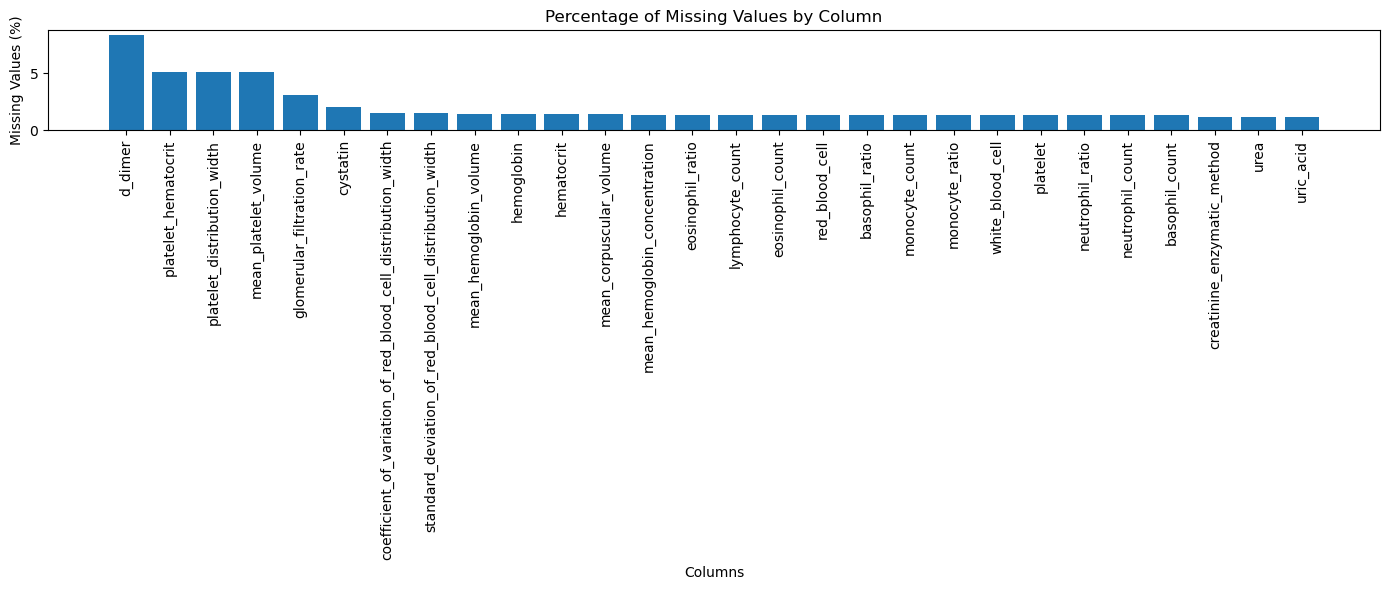

In [156]:

# Create a bar chart to visualize the NULL values

missing_summary = pd.DataFrame({
    'Column': dfLabs[my_lab_cols].columns,
    'Missing_Count': dfLabs[my_lab_cols].isnull().sum(),
    'Missing_Percentage': (dfLabs[my_lab_cols].isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

missing_plot = missing_summary[
    missing_summary['Missing_Count'] > 0
]

# Create a bar chart

plt.figure(figsize=(14, 6))

plt.bar(
    missing_plot['Column'],
    missing_plot['Missing_Percentage']
)

plt.xticks(rotation=90)

plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.title("Percentage of Missing Values by Column")

plt.tight_layout()
plt.show()

In [157]:
# Count completely duplicated rows

duplicate_count = dfLabs[my_lab_cols].duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [158]:
# Check whether every inpatient number is unique

unique_patient_ids = dfLabs[my_lab_cols]['inpatient_number'].nunique()

total_records = len(dfLabs[my_lab_cols])

print("Total records:", total_records)
print("Unique inpatient numbers:", unique_patient_ids)

Total records: 2008
Unique inpatient numbers: 2008


In [159]:
dfLabs[my_lab_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
inpatient_number,2008.0,797747.543,41127.802,722128.000,763164.500,798758.000,829399.750,905720.000
body_temperature,2008.0,36.416,0.440,35.000,36.200,36.300,36.500,42.000
pulse,2008.0,85.235,21.539,0.000,70.000,82.000,98.000,198.000
respiration,2008.0,19.086,1.738,0.000,18.000,19.000,19.000,36.000
systolic_blood_pressure,2008.0,131.057,24.742,0.000,113.000,130.000,146.250,252.000
diastolic_blood_pressure,2008.0,76.573,14.461,0.000,65.000,76.000,85.000,146.000
map_value,2008.0,94.734,16.324,0.000,83.333,93.333,104.667,181.333
fio2,2008.0,32.670,4.757,21.000,33.000,33.000,33.000,100.000
creatinine_enzymatic_method,1985.0,108.916,79.122,27.600,64.900,87.100,122.700,963.400
urea,1985.0,9.565,5.546,1.580,5.900,8.030,11.540,45.630


In [160]:
# check for any negative vlaues
(dfLabs[my_lab_cols] < 0).sum().loc[lambda x: x > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [161]:
# Count zero values in each column

zero_summary = pd.DataFrame({
    'Column': dfLabs[my_lab_cols].columns,
    'Zero_Count': [
        (dfLabs[my_lab_cols][column] == 0).sum()
        for column in dfLabs[my_lab_cols].columns
    ]
})


In [162]:
# Function to identify potential outliers using the IQR method

def find_outliers_iqr(data, column):
    
    # Calculate Q1 and Q3
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    
    # Calculate IQR
    IQR = Q3 - Q1
    
    # Calculate lower and upper limits
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    
    # Identify outliers
    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]
    
    return outliers, lower_limit, upper_limit

In [163]:
# Count Potential Outliers for every column
#Create an outlier summary

outlier_summary = []

# Loop through all columns except the patient ID

for column in dfLabs[my_lab_cols].columns[1:]:
    
    outliers, lower, upper = find_outliers_iqr(dfLabs[my_lab_cols], column)
    
    outlier_summary.append({
        'Column': column,
        'Lower_Limit': lower,
        'Upper_Limit': upper,
        'Outlier_Count': len(outliers),
        'Outlier_Percentage': round(
            len(outliers) / len(dfLabs[my_lab_cols]) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    by='Outlier_Count',
    ascending=False
)

,Column,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
30,platelet_distribution_width,15.100000,17.500000,266,13.25
6,fio2,33.000000,33.000000,248,12.35
2,respiration,16.500000,20.500000,246,12.25
34,d_dimer,-1.280000,4.240000,213,10.61
27,eosinophil_count,-0.145000,0.295000,174,8.67
21,mean_hemoglobin_volume,23.750000,36.950000,166,8.27
18,mean_corpuscular_volume,76.650000,109.050000,164,8.17
0,body_temperature,35.750000,36.950000,163,8.12
26,eosinophil_ratio,-0.025500,0.050500,154,7.67
7,creatinine_enzymatic_method,-21.800000,209.400000,142,7.07


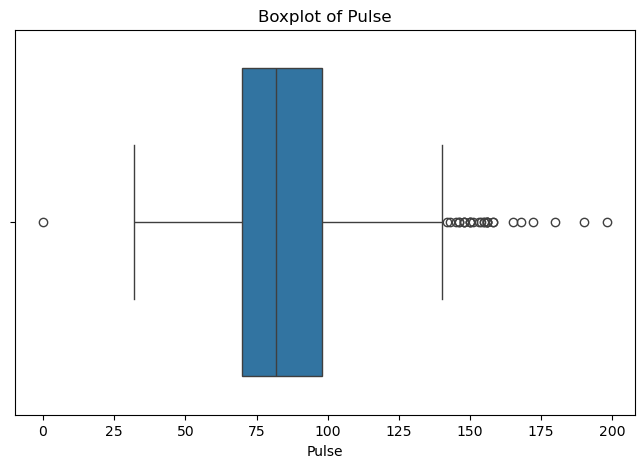

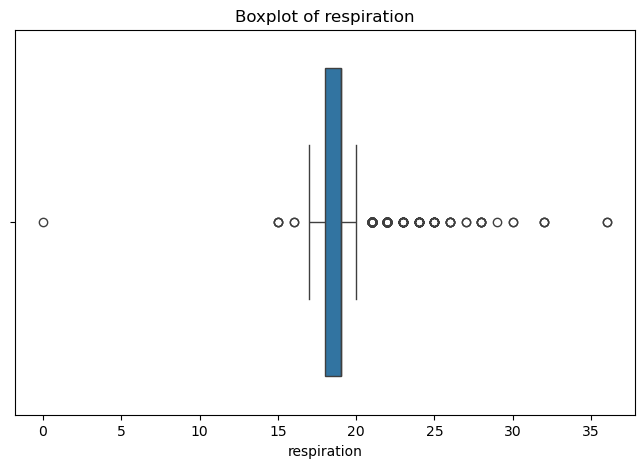

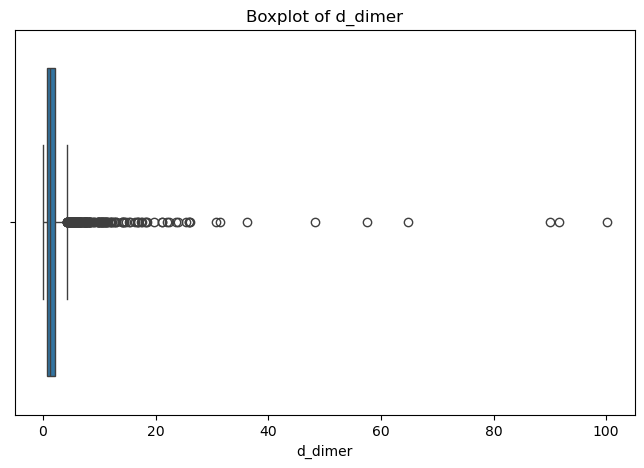

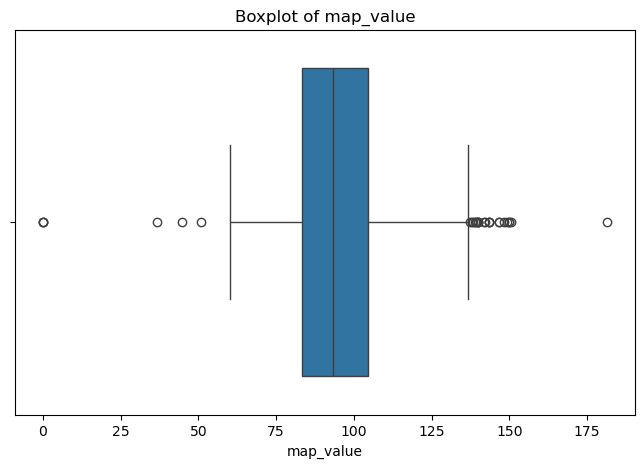

In [164]:
# check the outliers using box plot


plt.figure(figsize=(8, 5))

sns.boxplot(x=dfLabs[my_lab_cols]['pulse'])

plt.title("Boxplot of Pulse")
plt.xlabel("Pulse")

plt.show()

# Create a boxplot for respiration	

plt.figure(figsize=(8, 5))

sns.boxplot(x=dfLabs[my_lab_cols]['respiration'])

plt.title("Boxplot of respiration")
plt.xlabel("respiration")

plt.show()

# Create a boxplot for d_dimer	

plt.figure(figsize=(8, 5))

sns.boxplot(x=dfLabs[my_lab_cols]['d_dimer'])

plt.title("Boxplot of d_dimer")
plt.xlabel("d_dimer")

plt.show()

# Create a boxplot for map_value

plt.figure(figsize=(8, 5))

sns.boxplot(x=dfLabs[my_lab_cols]['map_value'])

plt.title("Boxplot of map_value")
plt.xlabel("map_value")

plt.show()

In [165]:
missing_summary[
    missing_summary['Missing_Count'] > 0
]

,Column,Missing_Count,Missing_Percentage
d_dimer,d_dimer,168,8.37
platelet_hematocrit,platelet_hematocrit,103,5.13
platelet_distribution_width,platelet_distribution_width,103,5.13
mean_platelet_volume,mean_platelet_volume,103,5.13
glomerular_filtration_rate,glomerular_filtration_rate,63,3.14
cystatin,cystatin,41,2.04
coefficient_of_variation_of_red_blood_cell_distribution_width,coefficient_of_variation_of_red_blood_cell_dis...,30,1.49
standard_deviation_of_red_blood_cell_distribution_width,standard_deviation_of_red_blood_cell_distribut...,30,1.49
mean_hemoglobin_volume,mean_hemoglobin_volume,28,1.39
hemoglobin,hemoglobin,28,1.39


In [166]:
labs_clean = dfLabs[my_lab_cols].copy()

In [167]:
zero_as_missing = [
    'pulse',
    'respiration',
    'systolic_blood_pressure',
    'diastolic_blood_pressure',
    'map_value'
]

for column in zero_as_missing:
    
    dfLabs.loc[
        dfLabs[column] == 0,
        column
    ] = np.nan

In [168]:
# Count Potential Outliers for every column
#Create an outlier summary

outlier_summary = []

# Loop through all columns except the patient ID

for column in labs_clean.columns[1:]:
    
    outliers, lower, upper = find_outliers_iqr(labs_clean, column)
    
    outlier_summary.append({
        'Column': column,
        'Lower_Limit': lower,
        'Upper_Limit': upper,
        'Outlier_Count': len(outliers),
        'Outlier_Percentage': round(
            len(outliers) / len(labs_clean) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    by='Outlier_Count',
    ascending=False
)

,Column,Lower_Limit,Upper_Limit,Outlier_Count,Outlier_Percentage
30,platelet_distribution_width,15.100000,17.500000,266,13.25
6,fio2,33.000000,33.000000,248,12.35
2,respiration,16.500000,20.500000,246,12.25
34,d_dimer,-1.280000,4.240000,213,10.61
27,eosinophil_count,-0.145000,0.295000,174,8.67
21,mean_hemoglobin_volume,23.750000,36.950000,166,8.27
18,mean_corpuscular_volume,76.650000,109.050000,164,8.17
0,body_temperature,35.750000,36.950000,163,8.12
26,eosinophil_ratio,-0.025500,0.050500,154,7.67
7,creatinine_enzymatic_method,-21.800000,209.400000,142,7.07


In [169]:
columns_in_scope = ['international_normalized_ratio',
'activated_partial_thromboplastin_time',
'thrombin_time',
'prothrombin_activity',
'prothrombin_time_ratio',
'fibrinogen',
'high_sensitivity_troponin',
'myoglobin',
'carbon_dioxide_binding_capacity',
'calcium',
'potassium',
'chloride',
'sodium',
'inorganic_phosphorus',
'serum_magnesium',
'creatine_kinase_isoenzyme_to_creatine_kinase',
'hydroxybutyrate_dehydrogenase_to_lactate_dehydrogenase',
'hydroxybutyrate_dehydrogenase',
'glutamic_oxaloacetic_transaminase',
'creatine_kinase',
'creatine_kinase_isoenzyme',
'lactate_dehydrogenase',
'brain_natriuretic_peptide',
'high_sensitivity_protein',
'nucleotidase',
'fucosidase',
'albumin',
'white_globulin_ratio',
'cholinesterase',
'glutamyltranspeptidase',
'glutamic_pyruvic_transaminase',
'glutamic_oxaliplatin',
'indirect_bilirubin',
'alkaline_phosphatase',
'globulin',
'direct_bilirubin',
'total_bilirubin',
'total_bile_acid']

In [170]:
# review dataset
dfLabs[columns_in_scope].describe()

,international_normalized_ratio,activated_partial_thromboplastin_time,thrombin_time,prothrombin_activity,prothrombin_time_ratio,fibrinogen,high_sensitivity_troponin,myoglobin,carbon_dioxide_binding_capacity,calcium,...,cholinesterase,glutamyltranspeptidase,glutamic_pyruvic_transaminase,glutamic_oxaliplatin,indirect_bilirubin,alkaline_phosphatase,globulin,direct_bilirubin,total_bilirubin,total_bile_acid
count,1973.00000,1974.000000,1974.000000,1962.000000,1973.000000,1974.000000,1929.000000,398.000000,1997.000000,1997.000000,...,0.0,1906.000000,1906.000000,592.000000,1906.000000,1906.000000,1906.000000,1906.000000,1906.000000,1498.000000
mean,1.34997,35.390172,17.244174,66.403262,1.353376,3.223830,0.281541,123.296206,23.816174,2.292944,...,NaN,61.068730,53.966264,1.371723,13.710283,89.479538,28.569412,9.024502,22.734785,8.554272
std,0.71393,8.308364,5.942134,18.448475,0.681233,1.044635,1.923464,140.220662,4.843350,0.180567,...,NaN,68.497133,204.022641,0.785210,9.249738,45.264134,6.057623,9.548840,17.485816,13.484040
min,0.83000,20.000000,9.700000,3.800000,0.850000,0.510000,0.000000,17.580000,2.100000,1.390000,...,NaN,5.000000,3.000000,0.010000,1.000000,19.000000,13.700000,0.300000,1.600000,0.000000
25%,1.13000,30.825000,16.300000,56.600000,1.130000,2.492500,0.023000,47.837500,20.900000,2.180000,...,NaN,22.000000,13.000000,0.910000,7.800000,64.000000,24.700000,4.100000,12.125000,2.600000
50%,1.21000,34.100000,17.200000,68.500000,1.220000,3.040000,0.055000,78.430000,23.900000,2.290000,...,NaN,39.000000,21.000000,1.200000,11.600000,80.000000,27.900000,6.500000,18.300000,4.700000
75%,1.35000,38.200000,17.900000,78.400000,1.360000,3.700000,0.119000,132.115000,26.700000,2.400000,...,NaN,74.000000,35.750000,1.655000,17.100000,102.000000,31.400000,10.500000,27.800000,8.800000
max,16.59000,181.900000,209.300000,141.510000,14.890000,8.320000,45.675000,994.820000,47.200000,3.370000,...,NaN,721.000000,4928.000000,11.140000,128.600000,1085.000000,88.300000,179.800000,256.600000,170.200000


In [171]:
# replacing NULLs with 0
dfLabs[columns_in_scope].fillna(0)

,international_normalized_ratio,activated_partial_thromboplastin_time,thrombin_time,prothrombin_activity,prothrombin_time_ratio,fibrinogen,high_sensitivity_troponin,myoglobin,carbon_dioxide_binding_capacity,calcium,...,cholinesterase,glutamyltranspeptidase,glutamic_pyruvic_transaminase,glutamic_oxaliplatin,indirect_bilirubin,alkaline_phosphatase,globulin,direct_bilirubin,total_bilirubin,total_bile_acid
0,1.39,33.4,17.0,60.30,1.37,3.84,0.094,0.0,21.6,2.28,...,0.0,83.0,65.0,1.02,11.4,61.0,23.8,6.9,18.3,4.9
1,1.16,35.9,18.4,65.10,1.18,2.62,0.017,0.0,26.5,2.28,...,0.0,17.0,19.0,0.00,13.1,69.0,25.4,5.2,18.3,2.4
2,1.10,36.2,14.9,85.70,1.09,5.74,0.010,0.0,21.6,2.56,...,0.0,27.0,10.0,1.10,7.5,76.0,27.7,4.4,11.9,2.4
3,1.37,38.3,18.3,60.90,1.36,2.63,0.349,0.0,21.1,2.35,...,0.0,134.0,9.0,0.00,26.2,191.0,27.0,25.4,51.6,9.4
4,1.19,34.6,16.4,74.90,1.19,3.50,0.115,0.0,22.8,2.42,...,0.0,17.0,19.0,0.00,6.9,61.0,29.6,4.9,11.8,3.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2003,1.08,25.3,17.8,83.33,1.08,2.01,0.028,0.0,24.6,2.40,...,0.0,27.0,6.0,0.00,7.8,59.0,33.5,4.5,12.3,1.9
2004,1.34,43.3,17.9,52.63,1.38,1.96,0.042,0.0,23.5,2.23,...,0.0,14.0,10.0,0.00,20.1,66.0,31.7,21.7,41.8,3.0
2005,1.27,38.6,20.4,67.80,1.27,1.68,0.470,0.0,24.0,2.34,...,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0
2006,2.26,30.6,16.0,22.70,2.41,4.31,0.129,0.0,19.3,2.37,...,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0


In [172]:
# check for percentage f null
# check for missing values perentage 
(dfLabs[columns_in_scope].isna().mean() * 100).sort_values(ascending=False)

cholinesterase                                            100.000000
myoglobin                                                  80.179283
inorganic_phosphorus                                       79.731076
serum_magnesium                                            79.731076
glutamic_oxaliplatin                                       70.517928
high_sensitivity_protein                                   53.137450
fucosidase                                                 26.344622
nucleotidase                                               26.344622
total_bile_acid                                            25.398406
glutamic_oxaloacetic_transaminase                          12.599602
creatine_kinase_isoenzyme_to_creatine_kinase               12.001992
lactate_dehydrogenase                                      12.001992
creatine_kinase_isoenzyme                                  12.001992
hydroxybutyrate_dehydrogenase                              12.001992
hydroxybutyrate_dehydrogenase_to_l

In [173]:
# Removing column cholinesterase  as it has 100 pecenage of null values
dfLabs = dfLabs.drop(columns=["cholinesterase"])

In [174]:
chol_lab_cols = [    "inpatient_number",    "total_protein",    "erythrocyte_sedimentation_rate",    "cholesterol",
    "low_density_lipoprotein_cholesterol",    "triglyceride",    "high_density_lipoprotein_cholesterol",
    "homocysteine",    "apolipoprotein_a",    "apolipoprotein_b",    "lipoprotein",    "ph",    "standard_residual_base",    "standard_bicarbonate",
    "partial_pressure_of_carbon_dioxide",    "total_carbon_dioxide",    "methemoglobin",    "hematocrit_blood_gas",    "reduced_hemoglobin",
    "potassium_ion",    "chloride_ion",    "sodium_ion",    "glucose_blood_gas",    "lactate",    "measured_residual_base",
    "measured_bicarbonate",    "carboxyhemoglobin",    "body_temperature_blood_gas",    "oxygen_saturation",    "partial_oxygen_pressure",
    "oxyhemoglobin",    "anion_gap",    "free_calcium",    "total_hemoglobin"
]

In [175]:
# check count of 0 values. 
(dfLabs[chol_lab_cols] == 0).sum().loc[lambda x: x > 0].sort_values(ascending=False)

methemoglobin             87
carboxyhemoglobin         36
measured_residual_base    13
standard_residual_base     8
dtype: int64

In [176]:
# check for missing values perentage 
(dfLabs[chol_lab_cols].isna().mean() * 100).sort_values(ascending=False)

homocysteine                            92.729084
lipoprotein                             91.235060
apolipoprotein_a                        91.235060
apolipoprotein_b                        91.235060
erythrocyte_sedimentation_rate          84.711155
hematocrit_blood_gas                    50.597610
oxyhemoglobin                           50.597610
carboxyhemoglobin                       50.597610
reduced_hemoglobin                      50.597610
methemoglobin                           50.597610
total_hemoglobin                        50.597610
ph                                      50.547809
standard_residual_base                  50.547809
free_calcium                            50.547809
anion_gap                               50.547809
partial_oxygen_pressure                 50.547809
oxygen_saturation                       50.547809
body_temperature_blood_gas              50.547809
measured_bicarbonate                    50.547809
measured_residual_base                  50.547809


In [177]:
# check for values countin high missing cols 
dfLabs[["homocysteine", "lipoprotein", "apolipoprotein_a", "apolipoprotein_b", "erythrocyte_sedimentation_rate"]].notna().sum()

homocysteine                      146
lipoprotein                       176
apolipoprotein_a                  176
apolipoprotein_b                  176
erythrocyte_sedimentation_rate    307
dtype: int64

### High Missingness
Removing 5 cols high missing values 91% ad 84%: homocysteine, lipoprotein, apolipoprotein_a, apolipoprotein_b, 
    and erythrocyte_sedimentation_rate.

In [178]:
dfLabs = dfLabs.drop(columns=[
    "homocysteine", "lipoprotein","apolipoprotein_a",  "apolipoprotein_b","erythrocyte_sedimentation_rate"])


remove_cols = { "homocysteine", "lipoprotein", "apolipoprotein_a",  "apolipoprotein_b", "erythrocyte_sedimentation_rate"}

chol_lab_cols = [col for col in chol_lab_cols if col not in remove_cols]


In [179]:
# checking min, max and count for all labs to find the outlier
dfLabs[chol_lab_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
inpatient_number,2008.0,797747.54,41127.80,722128.00,763164.50,798758.00,829399.75,905720.00
total_protein,1906.0,65.10,7.34,41.70,60.12,64.70,69.38,100.90
cholesterol,1810.0,3.72,1.09,1.20,2.97,3.60,4.32,10.00
low_density_lipoprotein_cholesterol,1810.0,1.86,0.76,0.35,1.32,1.76,2.29,6.41
triglyceride,1810.0,1.16,1.08,0.22,0.71,0.96,1.31,24.45
high_density_lipoprotein_cholesterol,1810.0,1.10,0.35,0.02,0.86,1.07,1.30,2.74
ph,993.0,7.41,0.07,6.77,7.39,7.42,7.45,7.60
standard_residual_base,993.0,-2.39,5.36,-32.70,-5.10,-2.20,0.50,24.90
standard_bicarbonate,993.0,22.99,3.91,2.60,21.00,23.00,25.00,42.70
partial_pressure_of_carbon_dioxide,993.0,35.80,9.56,12.00,30.00,34.00,39.00,143.00


In [180]:
# hematocrit_blood_gas max shows 111. lets check other realted vlaues.  
dfLabs.loc[
    dfLabs["hematocrit_blood_gas"] == dfLabs["hematocrit_blood_gas"].max(),
    ["inpatient_number", "hematocrit_blood_gas", "total_hemoglobin", "oxygen_saturation", "oxyhemoglobin"]
].T

,1806
inpatient_number,806289.0
hematocrit_blood_gas,111.0
total_hemoglobin,111.0
oxygen_saturation,99.0
oxyhemoglobin,98.9


### Hematocrit Outlier
hematocrit_blood_gas = 111.0 is a outlier and its retained.

In [181]:
# Total hemoglobin : High values were found, but they were also associated with high hematocrit values so no changes done.
dfLabs.loc[
    dfLabs["total_hemoglobin"] > 180,
    ["inpatient_number", "total_hemoglobin", "hematocrit_blood_gas"]
]

,inpatient_number,total_hemoglobin,hematocrit_blood_gas
137,860037,185.0,54.0
465,850791,189.0,56.0
499,729332,203.0,60.0
813,752701,187.0,55.0
991,831345,187.0,55.0
1000,764425,183.0,54.0
1026,849269,192.0,56.0
1727,841176,181.0,53.0


In [182]:
# Partial pressure of carbon dioxide : max value 143 was found and retained.
dfLabs.loc[
    dfLabs["partial_pressure_of_carbon_dioxide"] == dfLabs["partial_pressure_of_carbon_dioxide"].max(),
    ["inpatient_number", "partial_pressure_of_carbon_dioxide", "ph", "total_carbon_dioxide"]
].T

,891
inpatient_number,794077.00
partial_pressure_of_carbon_dioxide,143.00
ph,7.19
total_carbon_dioxide,57.50


In [183]:
### Glucose : max value 41 was found and retained as this is not data-entry error.
dfLabs.loc[
    dfLabs["glucose_blood_gas"] == dfLabs["glucose_blood_gas"].max(),
    ["inpatient_number", "glucose_blood_gas", "lactate"]
].T

,1861
inpatient_number,761283.0
glucose_blood_gas,41.0
lactate,1.7


In [184]:
# Lactate : max value of 19.9 was found and retained as this is not data-entry error.
dfLabs.loc[
    dfLabs["lactate"] == dfLabs["lactate"].max(),
    ["inpatient_number", "lactate", "ph", "partial_pressure_of_carbon_dioxide"]
].T

,1398
inpatient_number,828678.00
lactate,19.90
ph,6.81
partial_pressure_of_carbon_dioxide,12.00


In [185]:
### Measured bicarbonate : max value of 53.1 was found and retained as this is not data-entry error
dfLabs.loc[
    dfLabs["measured_bicarbonate"] == dfLabs["measured_bicarbonate"].max(),
    ["inpatient_number", "measured_bicarbonate", "standard_bicarbonate", "total_carbon_dioxide"]
].T

,891
inpatient_number,794077.0
measured_bicarbonate,53.1
standard_bicarbonate,42.7
total_carbon_dioxide,57.5


In [186]:
### Reduced hemoglobin : max value 74.7 was found and retained retained as this is not data-entry error.
dfLabs.loc[
    dfLabs["reduced_hemoglobin"] == dfLabs["reduced_hemoglobin"].max(),
    ["inpatient_number", "reduced_hemoglobin", "oxygen_saturation", "oxyhemoglobin"]
].T

,1029
inpatient_number,743489.0
reduced_hemoglobin,74.7
oxygen_saturation,25.0
oxyhemoglobin,24.3


In [187]:
# check for any negative vlaues
(dfLabs[chol_lab_cols] < 0).sum().loc[lambda x: x > 0].sort_values(ascending=False)

standard_residual_base    708
measured_residual_base    678
anion_gap                   2
dtype: int64

In [188]:
cols_to_check = [
    "inpatient_number",
    "sodium_ion",
    "chloride_ion",
    "standard_bicarbonate",
    "measured_bicarbonate",
    "total_carbon_dioxide",
    "anion_gap"
]

negative_anion_gap = dfLabs["anion_gap"] < 0

dfLabs.loc[negative_anion_gap, cols_to_check]

,inpatient_number,sodium_ion,chloride_ion,standard_bicarbonate,measured_bicarbonate,total_carbon_dioxide,anion_gap
801,810318,132.4,101.0,33.7,36.0,37.7,-1.2
891,794077,126.5,78.0,42.7,53.1,57.5,-0.8


### Negative values in standard_residual_base and measured_residual_base are valid.
#### The 2 outliers in anion_gap comparign with related lab values are not liekly data error, so we are retaining this values.

### Zero values
Zero values in methemoglobin, carboxyhemoglobin, measured_residual_base, and standard_residual_base were checked and retained as valid values.

In [189]:
# check for methemoglobin
dfLabs.loc[
    dfLabs["methemoglobin"] == 0,
    ["inpatient_number", "methemoglobin", "oxygen_saturation", "oxyhemoglobin"]
].head()

,inpatient_number,methemoglobin,oxygen_saturation,oxyhemoglobin
14,744167,0.0,99.0,98.6
47,865365,0.0,88.0,87.2
154,791071,0.0,97.0,96.5
206,780942,0.0,96.0,96.1
242,785494,0.0,96.0,95.3


### Methemoglobin : Zero values were checked and retained as valid values.

In [190]:
# check for carboxyhemoglobin
dfLabs.loc[
    dfLabs["carboxyhemoglobin"] == 0,
    ["inpatient_number", "carboxyhemoglobin", "methemoglobin", "oxygen_saturation"]
].head()

,inpatient_number,carboxyhemoglobin,methemoglobin,oxygen_saturation
171,810758,0.0,0.1,98.0
184,791588,0.0,0.2,96.0
203,813738,0.0,0.1,99.0
301,723617,0.0,0.3,98.0
435,788518,0.0,0.3,94.0


In [191]:
### Carboxyhemoglobin Zero values were checked and retained as valid values.

In [192]:
dfLabs.loc[
    dfLabs["measured_residual_base"] == 0,
    ["inpatient_number", "measured_residual_base", "standard_residual_base"]
].head()

,inpatient_number,measured_residual_base,standard_residual_base
164,738683,0.0,-0.1
215,821841,0.0,-0.1
287,819641,0.0,-0.6
481,859319,0.0,-0.5
519,839791,0.0,-0.8


### Measured residual base : Zero values were checked and retained as valid values.

In [193]:
dfLabs.loc[
    dfLabs["standard_residual_base"] == 0,
    ["inpatient_number", "standard_residual_base", "measured_residual_base"]
]

,inpatient_number,standard_residual_base,measured_residual_base
41,831189,0.0,0.3
543,760645,0.0,0.2
745,842847,0.0,0.3
762,758926,0.0,-0.1
862,727453,0.0,0.2
1021,859306,0.0,0.4
1459,772873,0.0,0.4
1605,820920,0.0,0.1


### Standard residual base : Zero values were checked and retained as valid values.

### Body temperature blood gas
All non-null values are 37.0, so this column has no variation and hence removed.

In [194]:
# removing this col as it has constant value 37
dfLabs = dfLabs.drop(columns=["body_temperature_blood_gas"])

In [195]:
dfLabs.shape

(2008, 100)

# End of Labs Cleaning

# 7. Patient Prescritpions Cleaning 

In [196]:
prescriptions_df.shape

(15362, 2)

In [197]:
#Find the actual columns

print("Columns:")
print(prescriptions_df.columns.tolist())

Columns:
['inpatient_number', 'drug_name']


In [198]:
#checking data type

print("Data types:")
print(prescriptions_df.dtypes)

Data types:
inpatient_number    int64
drug_name             str
dtype: object


In [199]:
#check missing value
print("Missing values:")
print(prescriptions_df.isna().sum())

Missing values:
inpatient_number    0
drug_name           0
dtype: int64


In [200]:
#check exact duplicate rows
print("Duplicate rows:",
      prescriptions_df.duplicated().sum())

Duplicate rows: 0


In [201]:
#validate Patient ID
print("Missing patient IDs:",
      prescriptions_df["inpatient_number"].isna().sum())

print("Unique patient IDs:",
      prescriptions_df["inpatient_number"].nunique())

print("Repeated patient IDs:",
      prescriptions_df["inpatient_number"].duplicated().sum())

Missing patient IDs: 0
Unique patient IDs: 2007
Repeated patient IDs: 13355


In [202]:
# column details
print(prescriptions_df.columns.tolist())


['inpatient_number', 'drug_name']


In [203]:
# 10 values 
print(prescriptions_df.head(10))

   inpatient_number                                         drug_name
0            857781                  sulfotanshinone sodium injection
1            857781                                 Furosemide tablet
2            857781                       Enoxaparin Sodium injection
3            857781  Meglumine Adenosine Cyclophosphate for injection
4            857781                              Furosemide injection
5            857781                               Milrinone injection
6            857781     Metoprolol Succinate Sustained-release tablet
7            857781                             Deslanoside injection
8            857781                                 Torasemide tablet
9            857781                   Benazepril hydrochloride tablet


In [204]:
#check missing drug name
print("Missing drug names:")
print(prescriptions_df["drug_name"].isna().sum())

Missing drug names:
0


In [205]:

#Check blank/empty drug names
blank_drugs = prescriptions_df[
    prescriptions_df["drug_name"].astype(str).str.strip().eq("")
]

print("Blank drug names:", len(blank_drugs))

print(blank_drugs)

Blank drug names: 0
Empty DataFrame
Columns: [inpatient_number, drug_name]
Index: []


In [206]:
#duplicate prescription value
duplicate_prescriptions = prescriptions_df[
    prescriptions_df.duplicated()
]

print("Duplicate prescription rows:",
      len(duplicate_prescriptions))

Duplicate prescription rows: 0


# End of Patient prescription validation:
### Patient Prescriptions: Patient identifiers were validated with no missing IDs. 
### Repeated patient IDs were retained because patients may have multiple prescription records. 
### Drug names were checked for missing/blank values and no defects were identified. 
### Duplicate prescription records were checked and none were found.

# End of Patient Prescritpions Cleaning 

# Merge all dataframes and Export the cleaned CSV file

In [207]:
df_final = demography_df.merge(cardiac_df, on="inpatient_number", how="inner") \
    .merge(hdDf, on="inpatient_number", how="inner") \
    .merge(dfLabs, on="inpatient_number", how="inner") \
    .merge(history_df, on="inpatient_number", how="inner") \
    .merge(responsiveness_df, on="inpatient_number", how="inner")

In [208]:
df_final.shape

(2008, 158)

In [209]:
df_final.head(2)

,inpatient_number,gender,weight,height,bmi,occupation,agecat,nyha_cardiac_function_classification,killip_grade,myocardial_infarction,...,liver_disease,aids,cci_score,type_ii_respiratory_failure,acute_renal_failure,eye_opening,verbal_response,movement,consciousness,gcs
0,827040,Female,50.0,1.45,23.781213,NaN,69-79,3,2,0,...,0.0,0,1.0,nontypeii,0,4,5,6,Clear,15
1,857781,Male,50.0,1.64,18.590125,UrbanResident,69-79,3,3,0,...,0.0,0,2.0,nontypeii,0,4,5,6,Clear,15


In [499]:
# Export Cleaned CSV file
df_final.to_csv(datasetPath / "10_PyMasters_Cleaned_Heartdata.csv", index=False)
prescriptions_df.to_csv(datasetPath / "10_PyMasters_Cleaned_Prescriptions.csv", index=False)

# After Exporting the Cleaned Data, Re-load the files verify the data.

In [500]:
# Re-load the Exported Cleaned files
dfPatient_Profile = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Heartdata.csv")
dfPrescriptions_cleaned = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Prescriptions.csv")

In [507]:
# verify the cleaned data 
dfPatient_Profile.shape

(2008, 158)

In [508]:
dfPrescriptions_cleaned.shape

(15362, 2)

In [509]:
dfPatient_Profile.head(2)

,inpatient_number,gender,weight,height,bmi,occupation,agecat,nyha_cardiac_function_classification,killip_grade,myocardial_infarction,...,liver_disease,aids,cci_score,type_ii_respiratory_failure,acute_renal_failure,eye_opening,verbal_response,movement,consciousness,gcs
0,827040,Female,50.0,1.45,23.781213,NaN,69-79,3,2,0,...,0.0,0,1.0,nontypeii,0,4,5,6,Clear,15
1,857781,Male,50.0,1.64,18.590125,UrbanResident,69-79,3,3,0,...,0.0,0,2.0,nontypeii,0,4,5,6,Clear,15


In [510]:
dfPrescriptions_cleaned.head(2)

,inpatient_number,drug_name
0,857781,sulfotanshinone sodium injection
1,857781,Furosemide tablet


# End of Data Cleaning, Ready for Analysis.